In [1]:
#!pip install scikeras

In [2]:
#basic libraries
import numpy as np
import pandas as pd

#visualisation libraries
import matplotlib.pyplot as plt
import pydot
import seaborn as sns

#evaluation libraries
from sklearn.metrics import confusion_matrix
from sklearn.metrics import accuracy_score
from sklearn.model_selection import GridSearchCV

#deep learning libraries
#code is written for an old version of Keras (Keras 2.x), but you are using Keras 3,
import tensorflow as tf
from tensorflow.keras import layers
import keras
from keras.models import Sequential
#from keras.layers.core import Dense,Activation,Dropout
from keras.layers import Dense, Activation, Dropout
#from keras.dataset import mnist
from tensorflow.keras.datasets import mnist
#from keras.utils.np_utils import to_categorical
from tensorflow.keras.utils import to_categorical
#from keras.wrappers.scikit_learn import KerasClassifier
from scikeras.wrappers import KerasClassifier


In [3]:
#loading dataset  -  digit mnist
(X_train_digit, y_train_digit), (X_test_digit, y_test_digit)=mnist.load_data()

In [4]:
#dataset images as input, text(eg:five) lable as output
X_train_digit

array([[[0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        ...,
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0]],

       [[0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        ...,
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0]],

       [[0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        ...,
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0]],

       ...,

       [[0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        ...,
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0]],

       [[0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        ...,
        [0, 0, 0, ..., 

In [5]:
y_train_digit

array([5, 0, 4, ..., 5, 6, 8], shape=(60000,), dtype=uint8)

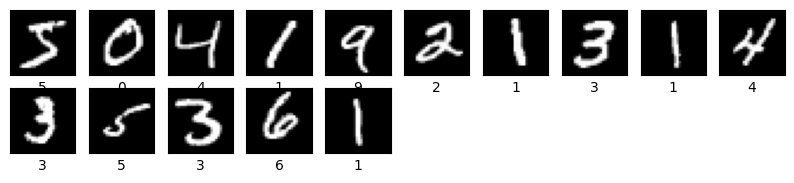

In [6]:
#names of numbers in the dataset in order
col_names=['zero','one','two','three','four','five','six','seven','eight','nine']

#visuvalising the digits
plt.figure(figsize=(10,10))
for i in range(15):
    #print ("hi")
    plt.subplot(10,10,i+1)
    plt.xticks([])
    plt.yticks([])
    plt.imshow(X_train_digit[i], cmap='gray' )
    plt.xlabel(col_names[y_train_digit[i]]) #printing  names of nos in xaxis
    plt.xlabel(y_train_digit[i]) #printing numbers dir in xaxis

plt.show()

In [7]:
#doubts
#array, direct display of numbers
#imshow if y_train
#plt.imshow(X_train_digit[i], cmap='gray')
#plt.xlabel(col_names[y_train_digit[i]])
#plt.show()

In [8]:
print (X_train_digit.shape)
print (X_test_digit.shape)
print (y_train_digit.shape)
print (y_test_digit.shape)

(60000, 28, 28)
(10000, 28, 28)
(60000,)
(10000,)


In [9]:
#converting 3d to 2d - preprocessing according to ANN
X_train_digit=X_train_digit.reshape(60000,784)
X_test_digit=X_test_digit.reshape(10000,784)

In [10]:
X_train_digit

array([[0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       ...,
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0]], shape=(60000, 784), dtype=uint8)

In [11]:
X_test_digit

array([[0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       ...,
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0]], shape=(10000, 784), dtype=uint8)

In [12]:
X_train_digit.shape

(60000, 784)

In [13]:
X_test_digit.shape

(10000, 784)

In [14]:
#output preprocessing
y_test_digit

array([7, 2, 1, ..., 4, 5, 6], shape=(10000,), dtype=uint8)

In [15]:
y_test_digit.shape

(10000,)

In [16]:
#the above result is 1D --> convert it to categorical --> one hot encoding
#0 to 9 ---> 10 classes
y_train_digit=to_categorical(y_train_digit,num_classes=10)
y_train_digit

array([[0., 0., 0., ..., 0., 0., 0.],
       [1., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       ...,
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 1., 0.]], shape=(60000, 10))

In [17]:
y_test_digit=to_categorical(y_test_digit,num_classes=10)
y_test_digit

array([[0., 0., 0., ..., 1., 0., 0.],
       [0., 0., 1., ..., 0., 0., 0.],
       [0., 1., 0., ..., 0., 0., 0.],
       ...,
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.]], shape=(10000, 10))

In [18]:
y_train_digit[1]
y_train_digit[2]
#y_train_digit[3]

array([0., 0., 0., 0., 1., 0., 0., 0., 0., 0.])

In [19]:
#3 parts, brain creation, compiling, fit method
#model creation - 1st part
#creating base neural network
model=keras.Sequential([
    layers.Dense(256, activation='relu', input_shape=(784,)),
    #layers.Dropout(0.3),  #same like revision test-reduced mark
    #layers.batchnormalization(),
    layers.Dense(64, activation='relu'),
    #layers.Dropout(0.3),
    #layers.batchnormalization(),
    layers.Dense(64, activation='relu'),
    #layers.Dropout(0.3),
    #layers.batchnormalization(),
    layers.Dense(10, activation='sigmoid'),  #always o/p layer, 10 label so 10 neuron
])

C:\Users\Meera\anaconda3\envs\ann\Lib\site-packages\keras\src\layers\core\dense.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [20]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense (Dense)                        │ (None, 256)                 │         200,960 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 64)                  │          16,448 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 64)                  │           4,160 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ (None, 10)                  │             650 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 222,218 (868.04 KB)

 Trainable params: 222,218 (868.04 KB)

 Non-trainable params: 0 (0.00 B)

In [21]:
#256*784=200960 ---> calculation of parameters in ANN
#param_number=output channel number * (input channel number+1)
#64*(256+1)=16448



In [22]:
#compiling the model - 2nd part
model.compile(loss="categorical_crossentropy",
              optimizer="adam",
              metrics=['accuracy'])

In [23]:
#fit method - 3rd part
history=model.fit(X_train_digit, y_train_digit, batch_size=100, epochs=10, validation_data=(X_test_digit, y_test_digit))

Epoch 1/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 5s 5ms/step - accuracy: 0.8371 - loss: 1.2145 - val_accuracy: 0.9093 - val_loss: 0.3592
Epoch 2/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 6s 10ms/step - accuracy: 0.9306 - loss: 0.2613 - val_accuracy: 0.9387 - val_loss: 0.2434
Epoch 3/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 6s 9ms/step - accuracy: 0.9498 - loss: 0.1767 - val_accuracy: 0.9428 - val_loss: 0.2037
Epoch 4/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 6s 10ms/step - accuracy: 0.9550 - loss: 0.1396 - val_accuracy: 0.9537 - val_loss: 0.1543
Epoch 5/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 6s 11ms/step - accuracy: 0.9584 - loss: 0.1207 - val_accuracy: 0.9504 - val_loss: 0.1533
Epoch 6/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 6s 10ms/step - accuracy: 0.9634 - loss: 0.1029 - val_accuracy: 0.9595 - val_loss: 0.1543
Epoch 7/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 6s 10ms/step - accuracy: 0.9655 - loss: 0.0954 - val_accuracy: 0.9533 - val_loss: 0.2153
Epoch 8/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 7s 12ms/step - accuracy: 0.9616 - loss: 0.0866 - val_accura

In [24]:
#predicting the labels-digit
y_predict=model.predict(X_test_digit)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step


In [25]:
y_predict

array([[3.4272437e-06, 1.1711643e-09, 9.9404132e-01, ..., 9.9999082e-01,
        1.1055157e-06, 9.8201311e-01],
       [1.8275844e-11, 2.7233271e-02, 9.9999821e-01, ..., 2.6747125e-06,
        2.3996517e-04, 3.1211648e-08],
       [9.9937606e-01, 1.0000000e+00, 9.9933344e-01, ..., 9.9992120e-01,
        2.7232138e-05, 9.9930733e-01],
       ...,
       [1.5361020e-09, 5.9027252e-06, 1.7209353e-05, ..., 3.8798142e-04,
        2.6975898e-03, 8.8354290e-01],
       [5.7320089e-17, 4.3770173e-16, 5.4246861e-15, ..., 1.6660211e-13,
        1.2631380e-04, 7.7709055e-01],
       [1.5315065e-01, 7.1837676e-01, 4.1283554e-01, ..., 7.0836252e-09,
        3.2749879e-01, 1.3222107e-10]], shape=(10000, 10), dtype=float32)

In [26]:
y_predicts=np.argmax(y_predict, axis=1) #here we get max value in encoded vector


In [27]:
y_predicts

array([7, 2, 1, ..., 4, 5, 6], shape=(10000,))

In [28]:
#y_train_digit[1]

In [33]:
y_test_digit_eval=np.argmax(y_test_digit, axis=1)

In [34]:
y_test_digit_eval

array([7, 2, 1, ..., 4, 5, 6], shape=(10000,))